# Telco customer Churn

Prediciting customer churn with logistic regression and random forest.
Data: Telco Customer churn dataset (7,043 customers,21 columns).


In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

RANDOM_STATE = 42

## Load the data

In [90]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Shape:", df.shape)

Shape: (7043, 21)


## Data inspection

In [91]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [92]:
print("Columns;")
for col in df.columns:
    print(" -",col)

Columns;
 - customerID
 - gender
 - SeniorCitizen
 - Partner
 - Dependents
 - tenure
 - PhoneService
 - MultipleLines
 - InternetService
 - OnlineSecurity
 - OnlineBackup
 - DeviceProtection
 - TechSupport
 - StreamingTV
 - StreamingMovies
 - Contract
 - PaperlessBilling
 - PaymentMethod
 - MonthlyCharges
 - TotalCharges
 - Churn


In [93]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [94]:
## Data preprocessing

In [95]:
# TotalCharges is text - blanks for zero tenure customers become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

df = df.dropna()
print("Shape after dropping missing rows:", df.shape)

Missing values in TotalCharges: 11
Shape after dropping missing rows: (7032, 21)


In [96]:
# customerID is a unique identifier with no predictive value.
df = df.drop(columns=["customerID"])
print("Shape after dropping customerID:", df.shape)

Shape after dropping customerID: (7032, 20)


In [97]:
df["Churn"] = (df["Churn"] == "Yes").astype(int) if df["Churn"].dtype == "object" else df["Churn"]
print(df["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [98]:
telecom_cust_dummies = pd.get_dummies(df, drop_first=True)
print("Shape:", telecom_cust_dummies.shape)
telecom_cust_dummies.head(10)

Shape: (7032, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
5,0,8,99.65,820.50,1,False,False,False,True,False,...,False,True,False,True,False,False,True,False,True,False
6,0,22,89.10,1949.40,0,True,False,True,True,False,...,False,True,False,False,False,False,True,True,False,False
7,0,10,29.75,301.90,0,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,True
8,0,28,104.80,3046.05,1,False,True,False,True,False,...,False,True,False,True,False,False,True,False,True,False
9,0,62,56.15,3487.95,0,True,False,True,True,False,...,False,False,False,False,True,False,False,False,False,False


'drop_first=True' drops one category per variable, avoiding the dummy variable trap. The dropped category becomes the basline.

In [99]:
telecom_cust_dummies = telecom_cust_dummies.astype(float)

## Data Visualisation

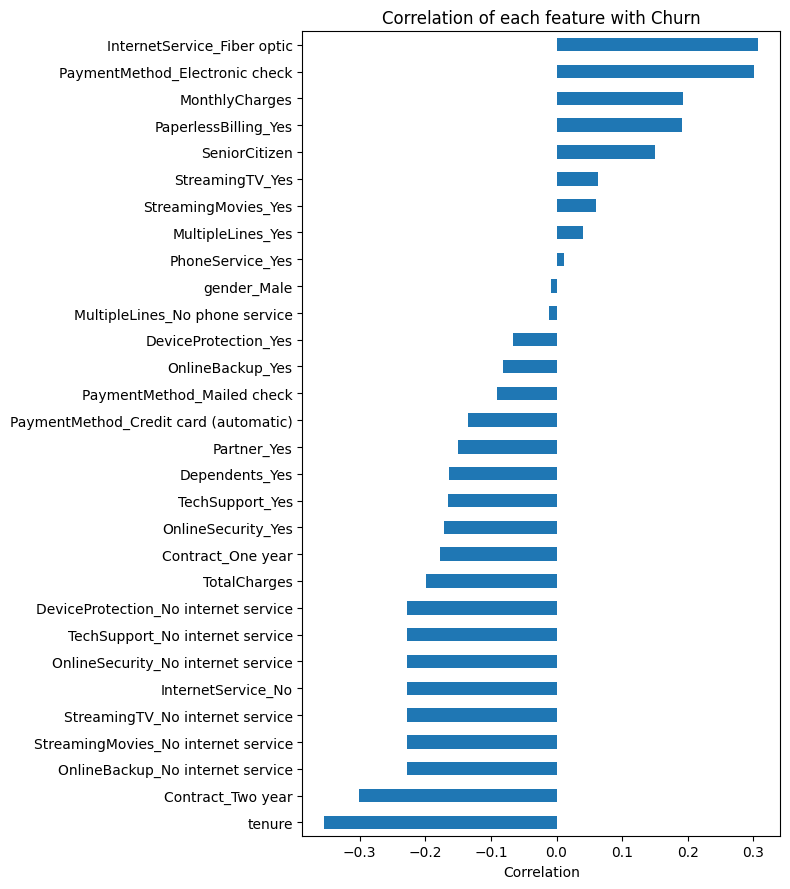

In [100]:
correlations = telecom_cust_dummies.corr() ["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(8,9))
correlations.plot(kind="barh")
plt.title("Correlation of each feature with Churn")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

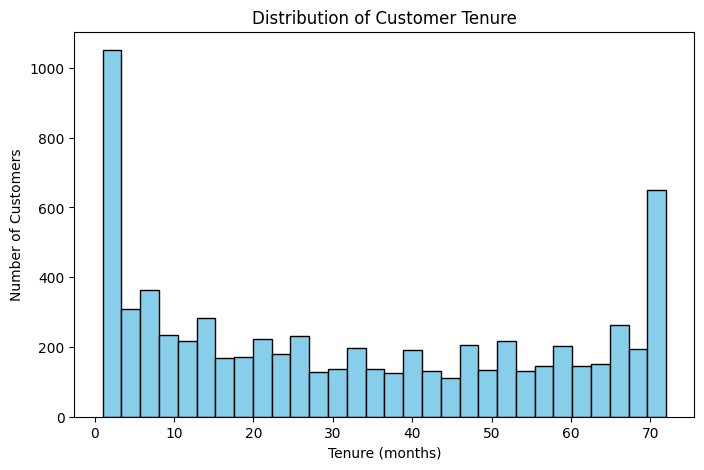

In [101]:
plt.figure(figsize=(8,5))
plt.hist(df["tenure"], bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Tenure")
plt.show()

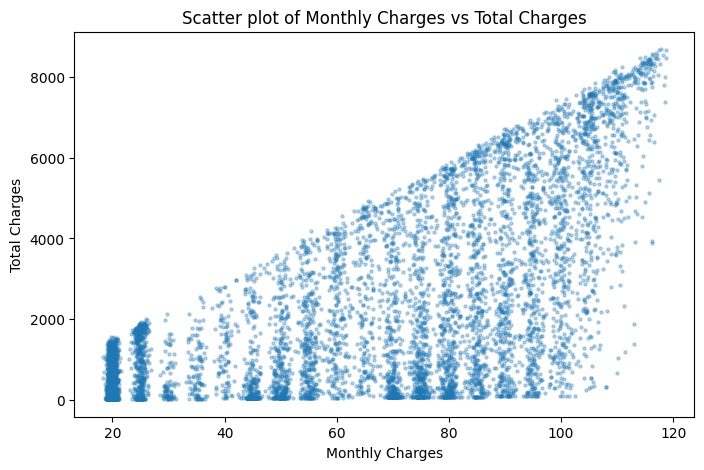

In [102]:
plt.figure(figsize=(8,5))
plt.scatter(df["MonthlyCharges"], df["TotalCharges"], s=5, alpha=0.3)
plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")
plt.title("Scatter plot of Monthly Charges vs Total Charges")
plt.show()

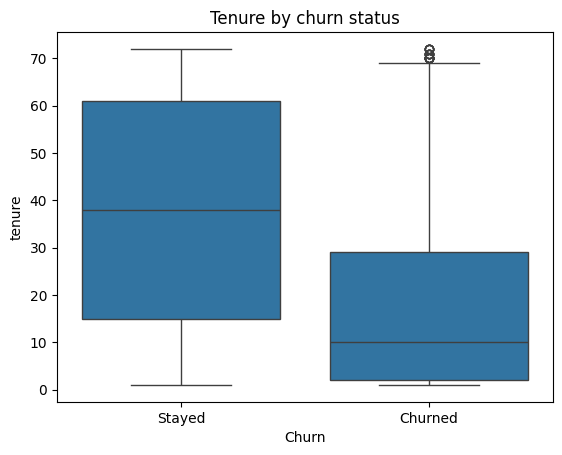

In [103]:
plt.Figure(figsize=(7,5))
sns.boxplot(x="Churn", y="tenure", data=df)
plt.xticks([0,1], ["Stayed","Churned"])
plt.title("Tenure by churn status")
plt.show()

## Preparations for ML training 

In [104]:
X = telecom_cust_dummies.drop(columns=["Churn"])
y = telecom_cust_dummies["Churn"]

# Min-max scaling puts every feature in the range [0,1] range so variables with large values (TotalCharges) don't dominate small ones (binary dummies).
scaler = MinMaxScaler()
X_scaled = pd.DataFrame (scaler.fit_transform(X), columns=X.columns)

X_scaled.describe().loc[["min","max"]]

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [105]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=RANDOM_STATE)

print("Training set:", X_train.shape[0], "customers")
print("Test set:", X_test.shape[0], "customers")


Training set: 5274 customers
Test set: 1758 customers


## Logistic regression model

In [106]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"logistic regression accuracy: {accuracy_lr:.4f}")

logistic regression accuracy: 0.7912


/Users/amiradiniz/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amiradiniz/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amiradiniz/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amiradiniz/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/amiradiniz/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ 

## Random forest model

In [107]:
rf = RandomForestClassifier(n_estimators=2000, oob_score=True, max_features="sqrt", max_leaf_nodes=50, bootstrap=True, random_state=RANDOM_STATE,n_jobs=1,)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")

Random Forest accuracy: 0.7935


In [108]:
oob_error = 1 - rf.oob_score_
print(f"OOB score: {rf.oob_score_:.4f}")
print(f"OOB error: {oob_error:.4f}")

OOB score: 0.8075
OOB error: 0.1925


**OOB error: 0.1925.** Each tree skips about a third of thr rows during training, so rows act as a free validation set. Classifying 81% of them correctly - close to the 79.35% test accuracy - shows the model generalises well rather than overfitting.

## Enhanced model evaluation

In [109]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Logistic regression:")
print(cm_lr)
print("Random forest:")
print(cm_rf)

Logistic regression:
[[1154  146]
 [ 221  237]]
Random forest:
[[1187  113]
 [ 250  208]]


In [110]:
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)


print(f"Logistic regression - precision: {precision_lr:.4f}, recall: {recall_lr:.4f}")
print(f"Random forest - precision: {precision_rf:.4f}, recall: {recall_rf:.4f}")



Logistic regression - precision: 0.6188, recall: 0.5175
Random forest - precision: 0.6480, recall: 0.4541


## 28. What the confusion matrix reveals

**Logistic regression:** 237 churners caught, 221 missed, 146 false alarms. **Random forest:** 208 caught, 250 missed 113 false alarms.
Both handle stayers well and struggle with churners , roughly half slip through. Precision beats recall in both: when a model flags someone it's right 62-65% of the time, but stays quiet on many who leave.With only 27% churn, predicting "stays" is the safer bet.
A False positive costs a needless discount; a false negative costs the customer. Recall matters more here, and both models are weak on it.

## 29. Model Comparison 

| Metric | Logisitic regression | Random forest|

| Accuracy | 0.7912 | 0.7935 |

| Precision | 0.6188 | 0.6480 |

| Recall | 0.5175 | 0.4541 |

Accuracy is tied. The forest is more precise; logistic regression finds 29 more churners.

**Logistic regression wins** - missing a churner costs more than a needless discount, so higher recall matters most. Lowering the threshold below 0.5 would trade precision for more recall still.
